# River-1 quickstart

Simulate the weekly MMM dataset of PyMC-Marketing's
[MMM example](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_example.html) by hand, load
River-1 from the Hub and decompose the sales: the model sees the outcome of the first 80% of the
weeks (context) and decomposes both the context and the remaining 20% (query), with no model fit.

Requires `pip install 'pymc-mfm[hub,diagnostics]'` and access to the private `pymc-labs/mfm`
repository (`hf auth login`).

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import torch

from pymc_mfm import decompose, from_pretrained

## 1. Load River-1

The bundle (about 10 MB) is downloaded into a temporary folder at a pinned repository commit.

In [2]:
workspace = TemporaryDirectory(prefix="river-1-")
model = from_pretrained(
    "pymc-labs/mfm",
    profile="river-1",
    revision="970e6095f14824d7e25ecace7e20a47bebde35b8",
    cache_dir=Path(workspace.name) / "hub",
)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
model.config

2,443,583 parameters


ModelConfig(d_model=128, n_layers=4, n_heads=8, d_ff=512, flow_hidden=256, n_controls=10, n_demand=1)

## 2. Generate the data

The PyMC-Marketing data-generating process: two channels with geometric adstock (8-week maximum
lag) and logistic saturation, a trend, yearly seasonality, two one-week events, an intercept and
Gaussian noise, in sales units (thousands). The series has 208 weeks, the history length River-1
was trained on.

In [3]:
seed = sum(map(ord, "mmm"))
rng = np.random.default_rng(seed=seed)
N_WEEKS = 208
dates = np.datetime64("2018-04-02") + 7 * np.arange(N_WEEKS)
dayofyear = (dates - dates.astype("datetime64[Y]")).astype(int) + 1

x1 = rng.uniform(low=0.0, high=1.0, size=N_WEEKS)
x1 = np.where(x1 > 0.9, x1, x1 / 2)
x2 = rng.uniform(low=0.0, high=1.0, size=N_WEEKS)
x2 = np.where(x2 > 0.8, x2, 0.0)


def geometric_adstock(x, alpha, l_max=8):
    weights = alpha ** np.arange(l_max)
    return np.convolve(x, weights / weights.sum())[: len(x)]


def logistic_saturation(x, lam):
    return (1 - np.exp(-lam * x)) / (1 + np.exp(-lam * x))

In [4]:
SCALE = 1_000
media = np.column_stack(
    [
        3.0 * logistic_saturation(geometric_adstock(x1, alpha=0.4), lam=4.0),
        2.0 * logistic_saturation(geometric_adstock(x2, alpha=0.2), lam=3.0),
    ]
)
trend = (np.linspace(start=0.0, stop=50, num=N_WEEKS) + 10) ** (1 / 4) - 1
seasonality = 0.5 * (
    -np.sin(2 * 2 * np.pi * dayofyear / 365.5) + np.cos(1 * 2 * np.pi * dayofyear / 365.5)
)
events = np.column_stack(
    [dates == np.datetime64("2019-05-13"), dates == np.datetime64("2020-09-14")]
).astype(float)
epsilon = rng.normal(loc=0.0, scale=0.25, size=N_WEEKS)

# True contributions in sales units.
baseline = SCALE * (2.0 + trend + seasonality)
channel_truth = SCALE * media
event_truth = SCALE * events * [1.5, 2.5]
y = baseline + channel_truth.sum(axis=1) + event_truth.sum(axis=1) + SCALE * epsilon

## 3. Split context and query

The model receives spend and controls for every week, but sales only for the context weeks.

166 context weeks, 42 query weeks


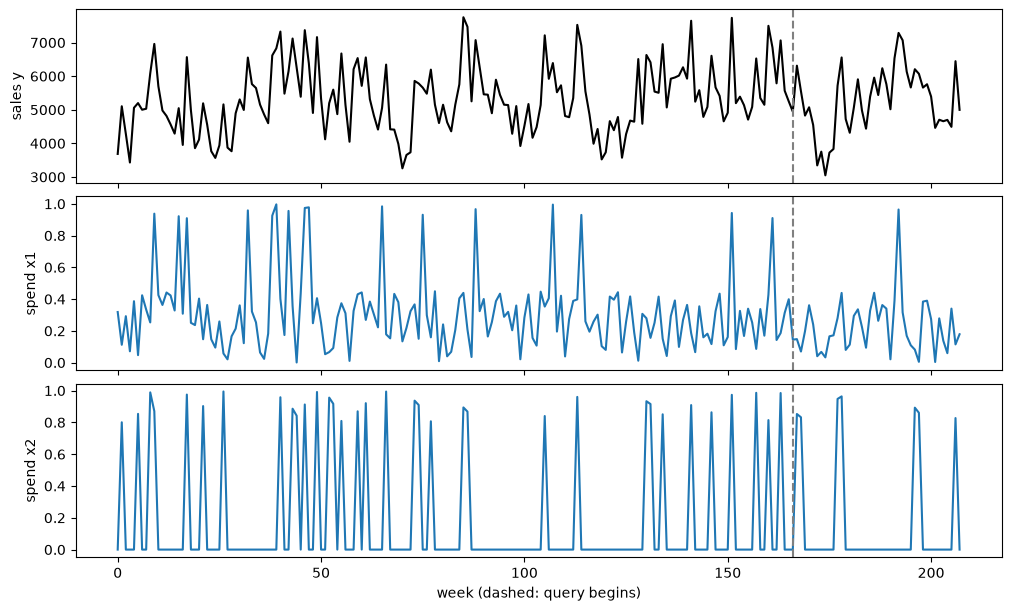

In [5]:
CONTEXT = int(0.8 * N_WEEKS)
print(f"{CONTEXT} context weeks, {N_WEEKS - CONTEXT} query weeks")

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True, layout="constrained")
for ax, values, label in zip(axes, (y, x1, x2), ("sales y", "spend x1", "spend x2"), strict=True):
    ax.plot(values, color="black" if label == "sales y" else None)
    ax.axvline(CONTEXT, color="0.5", linestyle="--")
    ax.set_ylabel(label)
axes[-1].set_xlabel("week (dashed: query begins)");

## 4. Decompose

River-1 has 10 control slots: the two events fill the first two and the mask marks the rest as
unused. Intercept, trend and seasonality belong to the model's baseline. Context and query are
decomposed separately, each with 1,000 posterior draws instead of the default 32.

In [6]:
controls = np.zeros((N_WEEKS, model.config.n_controls))
controls[:, :2] = events
observations = {
    "spend": np.column_stack([x1, x2]),
    "controls": controls,
    "context_outcome": y[:CONTEXT],
    "control_mask": [1, 1] + [0] * (model.config.n_controls - 2),
}
names = {
    "channel_names": ("x1", "x2"),
    "control_names": ("event_1", "event_2", *(f"unused_{i}" for i in range(2, 10))),
}
torch.manual_seed(0)
context = decompose(model, observations, n_samples=1_000, window="context", **names)
query = decompose(model, observations, n_samples=1_000, window="query", **names)
query.components.shape  # [draw, week, component]

(1000, 42, 17)

## 5. Contributions

Window totals against the truth, with the x1 share of media contribution (0.81 over the
PyMC-Marketing example's 179 weeks):

In [7]:
def compare(result, weeks):
    truth = {
        "baseline": baseline[weeks],
        "channel:x1": channel_truth[weeks, 0],
        "channel:x2": channel_truth[weeks, 1],
    }
    print(f"{result.window} window ({result.components.shape[1]} weeks)")
    means = {}
    for name, values in truth.items():
        draws = result.components[:, :, result.component_names.index(name)].sum(axis=1)
        low, high = np.quantile(draws, [0.05, 0.95])
        means[name] = draws.mean()
        print(
            f"  {name:<11} truth {values.sum():>9,.0f}  "
            f"posterior mean {means[name]:>9,.0f}  90% [{low:,.0f}, {high:,.0f}]"
        )
    true_share = truth["channel:x1"].sum() / (truth["channel:x1"] + truth["channel:x2"]).sum()
    share = means["channel:x1"] / (means["channel:x1"] + means["channel:x2"])
    print(f"  x1 share    truth {true_share:.2f}  posterior mean {share:.2f}")


compare(context, slice(None, CONTEXT))
compare(query, slice(CONTEXT, None))

context window (166 weeks)
  baseline    truth   549,086  posterior mean   491,523  90% [373,507, 605,464]
  channel:x1  truth   261,603  posterior mean   205,599  90% [124,996, 280,093]
  channel:x2  truth    70,252  posterior mean    62,515  90% [52,521, 73,018]
  x1 share    truth 0.79  posterior mean 0.77
query window (42 weeks)
  baseline    truth   155,333  posterior mean   150,104  90% [97,210, 202,096]
  channel:x1  truth    51,407  posterior mean    33,646  90% [21,417, 47,060]
  channel:x2  truth    13,690  posterior mean    12,833  90% [10,375, 15,513]
  x1 share    truth 0.79  posterior mean 0.72


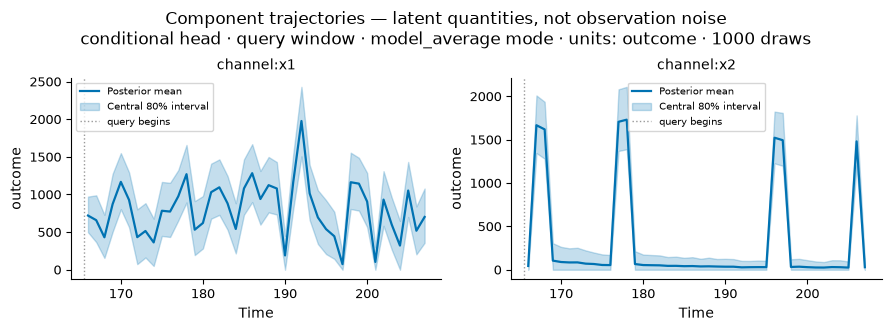

In [8]:
query.plot.channels()

## 6. Sales in the query weeks

The sum of the components is the model's sales in weeks whose outcome it never saw; it excludes
observation noise.

mean absolute error 760
held-out weeks inside the 90% interval: 90%


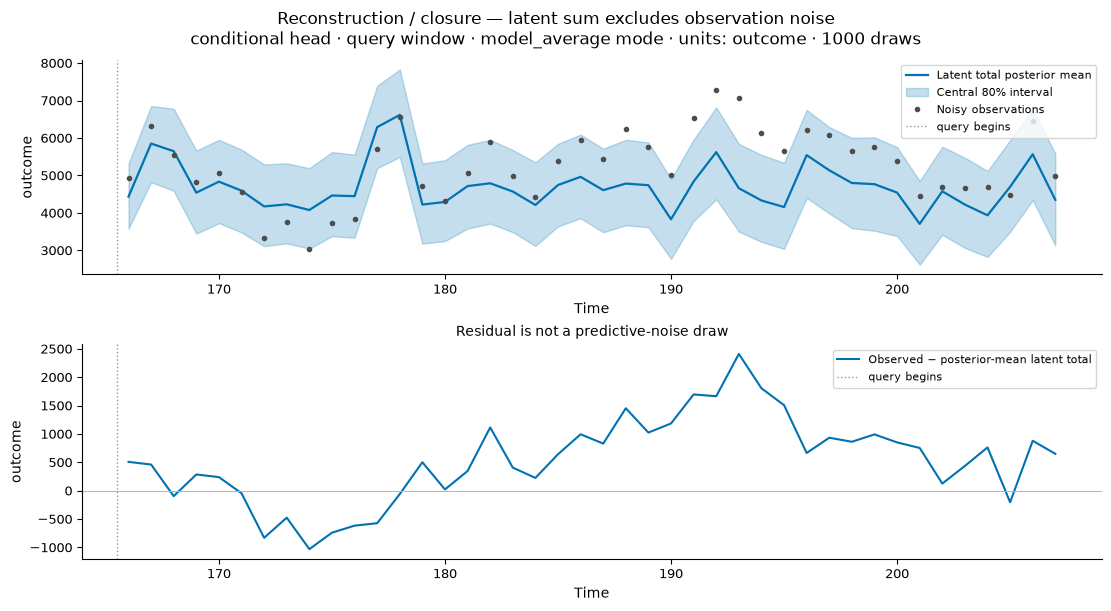

In [9]:
sales = query.components.sum(axis=2)
low, high = np.quantile(sales, [0.05, 0.95], axis=0)
held_out = y[CONTEXT:]
print(f"mean absolute error {np.abs(sales.mean(axis=0) - held_out).mean():,.0f}")
print(
    f"held-out weeks inside the 90% interval: {np.mean((low <= held_out) & (held_out <= high)):.0%}"
)
query.plot.reconstruction(observed=held_out)

## 7. Recovery

Every component's posterior mean against its truth, in the result's component order (baseline,
channels, controls, latent, indirect).

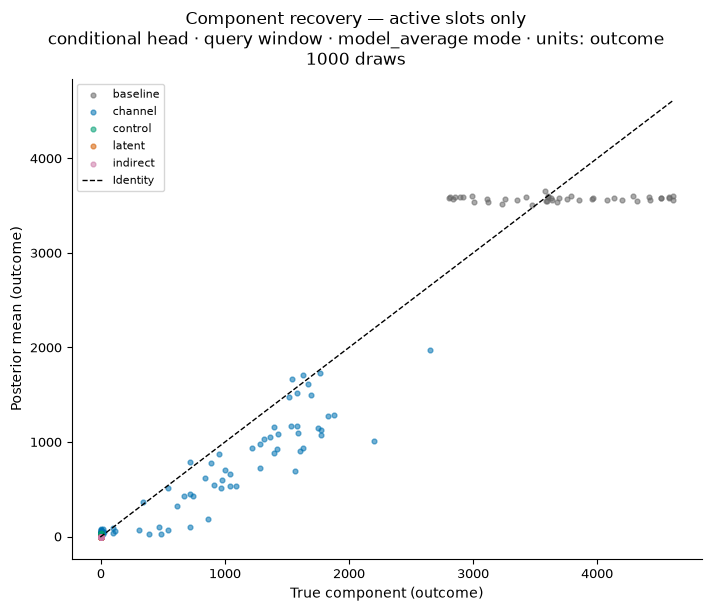

In [10]:
truth = np.column_stack(
    [baseline, channel_truth, event_truth, np.zeros((N_WEEKS, len(query.component_names) - 5))]
)
diagnostics = query.diagnostics(truth=truth[CONTEXT:], observed=held_out)
diagnostics.plot.recovery()

In [11]:
workspace.cleanup()  # Delete the downloaded bundle.